#### DSC550-T302 Data Mining
#### Term Project
#### Week 10
#### Milestones 1, 2 & 3
#### Kyle Gotzman

#### Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, f1_score, accuracy_score)

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.05)
plt.rcParams.update({
    'figure.dpi': 96,
    'figure.facecolor': 'white',
    'axes.facecolor': '#fafafa',
    'axes.edgecolor': '#cccccc',
    'grid.color': '#e0e0e0',
})

## Business Problem

**Predicting Positive and Negative Market Segment Reactions to Tariff Announcements**

Tariff announcements do not affect all industries equally. Some market segments may decline due to higher input costs or supply-chain disruption, while others may benefit from protectionist policies. This project examines whether tariff announcements can predict positive or negative short-term returns across U.S. market sector ETFs spanning 11 industries, using daily return behavior around 45 major tariff events from 2018 through 2025.

The data comes from two sources: a **sector impact** dataset (33,000+ daily observations of sector ETF performance) and a **tariff timeline** dataset (45 tariff actions with imposing/target country, rate changes, and estimated trade value). The key hypothesis is that **tariff shocks create winners and losers across market segments** rather than one uniform response.

In [2]:
sector_impact = pd.read_csv('sector_impact.csv', parse_dates=['date'])
tariff_timeline = pd.read_csv('tariff_timeline.csv', parse_dates=['date'])

print(f"Sector Impact:   {sector_impact.shape[0]:,} rows × {sector_impact.shape[1]} columns")
print(f"Tariff Timeline: {tariff_timeline.shape[0]:,} rows × {tariff_timeline.shape[1]} columns")
print(f"Sectors ({sector_impact['sector'].nunique()}): {', '.join(sorted(sector_impact['sector'].unique()))}")
print(f"Date range: {sector_impact['date'].min().date()} to {sector_impact['date'].max().date()}")
print(f"Tariff events span {tariff_timeline['date'].min().date()} to {tariff_timeline['date'].max().date()}")

Sector Impact:   33,344 rows × 15 columns
Tariff Timeline: 45 rows × 16 columns
Sectors (15): Agriculture, Automobiles, Clean Energy, Consumer Discretionary, Emerging Markets, Energy, Financials, Healthcare, Industrials, Materials, Mining & Materials, Retail, Semiconductors, Steel & Metals, Technology
Date range: 2018-01-02 to 2026-04-17
Tariff events span 2018-03-08 to 2026-04-13


### Prepare the Analysis Dataset

Map each tariff date to the nearest trading day (within 3-day tolerance). "Post-tariff" means the **same-day close-to-close return**. Multiple tariff actions on the same date are aggregated, not double-counted.

In [3]:
# Build sorted DatetimeIndex arrays for reliable searching
trading_dates = pd.DatetimeIndex(sector_impact['date'].unique()).sort_values()
tariff_dates = pd.DatetimeIndex(tariff_timeline['date'].unique()).sort_values()

# Map each tariff announcement to the nearest actual trading day (within 3 days)
matched_dates = []
for td in tariff_dates:
    idx = trading_dates.searchsorted(td)
    candidates = []
    if idx < len(trading_dates):
        candidates.append(trading_dates[idx])
    if idx > 0:
        candidates.append(trading_dates[idx - 1])
    best = min(candidates, key=lambda x: abs(x - td))
    if abs(best - td) <= pd.Timedelta(days=3):
        matched_dates.append(best)

matched_dates = sorted(set(matched_dates))

# Filter sector returns to only tariff-event trading days
event_returns = sector_impact[sector_impact['date'].isin(matched_dates)].copy()
event_returns = event_returns.dropna(subset=['daily_return_pct'])

# Label each observation as Positive, Negative, or Neutral based on daily return
event_returns['reaction'] = np.where(
    event_returns['daily_return_pct'] > 0, 'Positive',
    np.where(event_returns['daily_return_pct'] < 0, 'Negative', 'Neutral')
)

print(f"Tariff events mapped to {len(matched_dates)} unique trading days")
print(f"Sector-event observations: {len(event_returns):,}")
print(f"Sectors represented: {event_returns['sector'].nunique()}")

Tariff events mapped to 33 unique trading days
Sector-event observations: 528
Sectors represented: 15


## Graphical Analysis

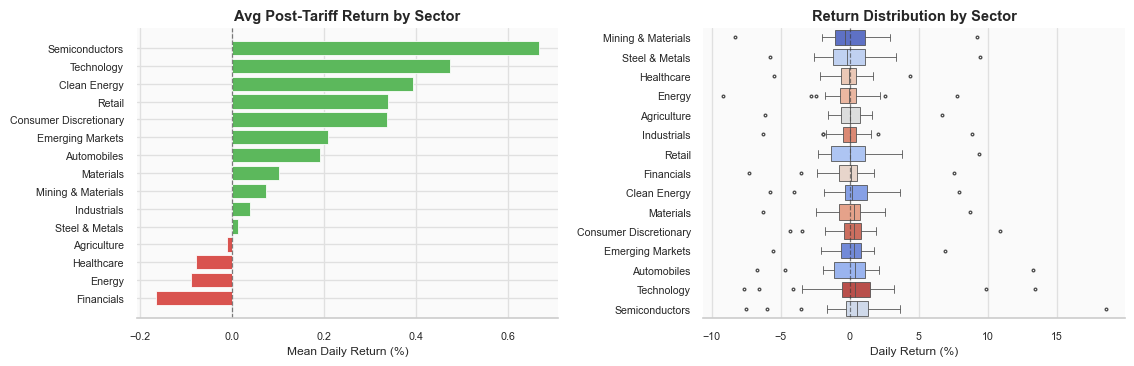

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Graph 1: Average return by sector
avg_returns = event_returns.groupby('sector')['daily_return_pct'].mean().sort_values()
colors = ['#d9534f' if v < 0 else '#5cb85c' for v in avg_returns.values]
ax1.barh(avg_returns.index, avg_returns.values, color=colors, edgecolor='white', linewidth=0.6)
ax1.axvline(0, color='#333333', linewidth=0.9, linestyle='--', alpha=0.6)
ax1.set_xlabel('Mean Daily Return (%)', fontsize=9)
ax1.set_title('Avg Post-Tariff Return by Sector', fontsize=11, fontweight='bold')
ax1.tick_params(labelsize=8)

# Graph 2: Distribution of returns by sector
sector_order = event_returns.groupby('sector')['daily_return_pct'].median().sort_values().index
sns.boxplot(data=event_returns, y='sector', x='daily_return_pct',
            order=sector_order, hue='sector', palette='coolwarm_r',
            fliersize=2, linewidth=0.6, legend=False, ax=ax2)
ax2.axvline(0, color='#333333', linewidth=0.9, linestyle='--', alpha=0.6)
ax2.set_xlabel('Daily Return (%)', fontsize=9)
ax2.set_ylabel('')
ax2.set_title('Return Distribution by Sector', fontsize=11, fontweight='bold')
ax2.tick_params(labelsize=8)

sns.despine(left=True)
plt.tight_layout()
plt.show()

**Graphs 1-2 Analysis:** Average post-tariff returns vary meaningfully across sectors: Financials and Energy post the most negative averages while Semiconductors and Technology lead positively. The boxplots show that even sectors near zero exhibit wide interquartile ranges, meaning reaction direction depends on event specifics, not just sector identity. This confirms the core hypothesis that tariffs create heterogeneous winners and losers.

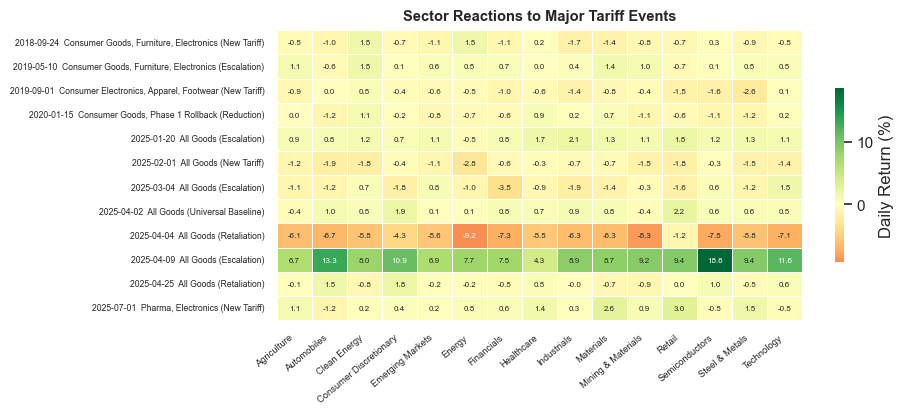

In [5]:
# Heatmap of sector reactions to the 12 largest tariff events
top_events = (tariff_timeline
              .sort_values('estimated_trade_value_usd_bn', ascending=False)
              .drop_duplicates(subset='date').head(12).sort_values('date'))
top_events['label'] = (top_events['date'].dt.strftime('%Y-%m-%d') + '  ' +
                        top_events['sector'] + ' (' + top_events['type'] + ')')

event_date_map = {}
for _, row in top_events.iterrows():
    td = row['date']
    idx = trading_dates.searchsorted(td)
    candidates = []
    if idx < len(trading_dates): candidates.append(trading_dates[idx])
    if idx > 0: candidates.append(trading_dates[idx - 1])
    best = min(candidates, key=lambda x: abs(x - td))
    if abs(best - td) <= pd.Timedelta(days=3):
        event_date_map[row['label']] = best

heatmap_data = event_returns[event_returns['date'].isin(event_date_map.values())].copy()
label_lookup = {v: k for k, v in event_date_map.items()}
heatmap_data['event_label'] = heatmap_data['date'].map(label_lookup)
heatmap_data = heatmap_data.dropna(subset=['event_label'])
pivot = heatmap_data.pivot_table(index='event_label', columns='sector',
                                  values='daily_return_pct', aggfunc='mean')
pivot = pivot.loc[list(event_date_map.keys())]

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.heatmap(pivot, cmap='RdYlGn', center=0, annot=True, fmt='.1f',
            annot_kws={'size': 6}, linewidths=0.4, linecolor='white',
            cbar_kws={'label': 'Daily Return (%)', 'shrink': 0.6}, ax=ax)
ax.set_title('Sector Reactions to Major Tariff Events', fontsize=11, fontweight='bold', pad=8)
ax.set_xlabel('')
ax.set_ylabel('')
plt.xticks(rotation=40, ha='right', fontsize=7)
plt.yticks(fontsize=6.5)
plt.tight_layout()
plt.show()

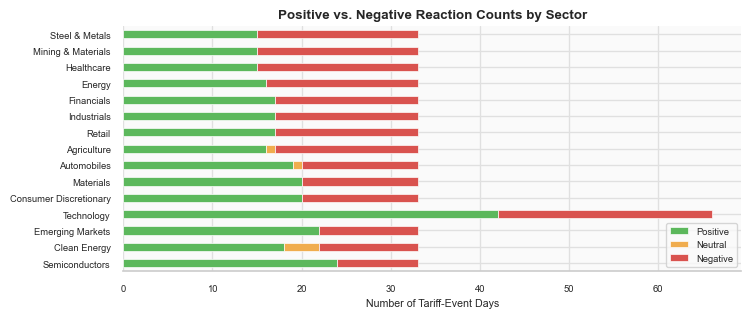

In [6]:
# Positive vs. Negative reaction counts by sector
reaction_counts = event_returns.groupby(['sector', 'reaction']).size().unstack(fill_value=0)
for col in ['Positive', 'Neutral', 'Negative']:
    if col not in reaction_counts.columns:
        reaction_counts[col] = 0
reaction_counts = reaction_counts[['Positive', 'Neutral', 'Negative']]
reaction_counts['neg_share'] = reaction_counts['Negative'] / reaction_counts.sum(axis=1)
reaction_counts = reaction_counts.sort_values('neg_share')

fig, ax = plt.subplots(figsize=(8, 3.5))
reaction_counts[['Positive', 'Neutral', 'Negative']].plot.barh(
    stacked=True, color=['#5cb85c', '#f0ad4e', '#d9534f'],
    edgecolor='white', linewidth=0.5, ax=ax)
ax.set_xlabel('Number of Tariff-Event Days', fontsize=8)
ax.set_ylabel('')
ax.set_title('Positive vs. Negative Reaction Counts by Sector', fontsize=10, fontweight='bold')
ax.legend(loc='lower right', fontsize=7)
ax.tick_params(labelsize=7)
sns.despine(left=True)
plt.tight_layout()
plt.show()

**Graphs 3-4 Analysis:** The heatmap shows broad-based tariffs move most sectors in the same direction, while targeted actions produce differentiated patterns. The stacked bar chart shows most sectors have a fairly balanced mix of positive and negative reaction days, confirming the prediction task is non-trivial.

## Milestone 1: Conclusion

Tariff announcements affect sectors unevenly. The balanced class split (positive vs. negative) makes this well-suited for binary classification.

---

## Milestone 2: Data Preparation

### Steps 1-3: Clean and Scope the Data

In [7]:
# Step 1: Drop unhelpful features
sector_impact = sector_impact.drop(columns=['sector_label', 'open', 'high', 'low', 'close', 'volume', 'indexed_to_100'])
tariff_timeline = tariff_timeline.drop(columns=['source', 'notes', 'quarter', 'month', 'prev_rate_pct'])

# Step 2: Restrict to U.S. sector ETFs
sector_impact = sector_impact[sector_impact['country'] == 'USA'].copy()
sector_impact = sector_impact.drop(columns=['country'])

# Step 3: Rebuild event_returns from U.S.-only data; confirm no NaN rows lost
trading_dates = pd.DatetimeIndex(sector_impact['date'].unique()).sort_values()
tariff_dates = pd.DatetimeIndex(tariff_timeline['date'].unique()).sort_values()
matched_dates = []
for td in tariff_dates:
    idx = trading_dates.searchsorted(td)
    candidates = []
    if idx < len(trading_dates): candidates.append(trading_dates[idx])
    if idx > 0: candidates.append(trading_dates[idx - 1])
    best = min(candidates, key=lambda x: abs(x - td))
    if abs(best - td) <= pd.Timedelta(days=3):
        matched_dates.append(best)
matched_dates = sorted(set(matched_dates))
event_returns = sector_impact[sector_impact['date'].isin(matched_dates)].copy()
event_returns = event_returns.dropna(subset=['daily_return_pct'])

print(f"U.S. sectors: {sector_impact['sector'].nunique()}  |  "
      f"Tariff event days: {len(matched_dates)}  |  "
      f"Event-return rows: {len(event_returns)}")

U.S. sectors: 11  |  Tariff event days: 33  |  Event-return rows: 363


### Step 4: Feature Engineering

In [8]:
# A. Tariff-event features (aggregate across same-date events)
median_trade_val = tariff_timeline['estimated_trade_value_usd_bn'].median()
tariff_timeline['estimated_trade_value_usd_bn'] = tariff_timeline['estimated_trade_value_usd_bn'].fillna(median_trade_val)

tariff_event_agg = (
    tariff_timeline.groupby('date').agg(
        max_tariff_rate_delta=('tariff_rate_delta', 'max'),
        max_tariff_rate_pct=('tariff_rate_pct', 'max'),
        max_trade_value_bn=('estimated_trade_value_usd_bn', 'max'),
        n_events=('tariff_rate_delta', 'count'),
        any_retaliation=('retaliation', 'max'),
    ).reset_index()
)
tariff_event_agg['is_usa_imposing'] = (
    tariff_timeline.groupby('date')['imposing_country']
    .apply(lambda x: int((x == 'USA').any())).values
)
tariff_event_agg = tariff_event_agg.rename(columns={'date': 'trading_date'})
tariff_event_agg['trading_date'] = tariff_event_agg['trading_date'].map(
    lambda d: min(matched_dates, key=lambda x: abs(x - d))
)
# Re-aggregate when multiple tariff dates map to the same trading day (FIXED SINCE MILESTONE 3)
tariff_event_agg = tariff_event_agg.groupby('trading_date').agg({
    'max_tariff_rate_delta': 'max',
    'max_tariff_rate_pct': 'max',
    'max_trade_value_bn': 'max',
    'n_events': 'sum',
    'any_retaliation': 'max',
    'is_usa_imposing': 'max',
}).reset_index()
event_returns = event_returns.merge(tariff_event_agg, left_on='date', right_on='trading_date', how='left'
).drop(columns=['trading_date'])

# B. Prior-day S&P 500 return (avoids same-day leakage) + 20-day volatility
stock_market = pd.read_csv('stock_market_reaction.csv', parse_dates=['date'])
sp500 = stock_market[stock_market['ticker'] == '^GSPC'][['date', 'daily_return_pct', 'volatility_20d']].copy()
sp500 = sp500.sort_values('date')
sp500['sp500_return_prev1d'] = sp500['daily_return_pct'].shift(1)
sp500 = sp500.rename(columns={'volatility_20d': 'sp500_volatility_20d'})
sp500 = sp500[['date', 'sp500_return_prev1d', 'sp500_volatility_20d']]
event_returns = event_returns.merge(sp500, on='date', how='left')

# C. Pre-event 5-day sector momentum
momentum_records = []
for _, row in event_returns[['date', 'sector']].drop_duplicates().iterrows():
    sector_ts = sector_impact[
        (sector_impact['sector'] == row['sector']) & (sector_impact['date'] < row['date'])
    ].sort_values('date').tail(5)
    if len(sector_ts) == 5:
        cum_return = (1 + sector_ts['daily_return_pct'] / 100).prod() - 1
        momentum_records.append({'date': row['date'], 'sector': row['sector'],
                                  'sector_momentum_5d': cum_return * 100})
event_returns = event_returns.merge(pd.DataFrame(momentum_records), on=['date', 'sector'], how='left')
event_returns['sector_momentum_5d'] = event_returns['sector_momentum_5d'].fillna(0)

# D. Encode tariff sensitivity
event_returns['tariff_sensitivity_ord'] = event_returns['tariff_sensitivity'].map({'Low': 1, 'Medium': 2, 'High': 3})

print(f"Features engineered. Shape: {event_returns.shape}")

Features engineered. Shape: (363, 17)


### Steps 5-6: Define Target, Encode Sectors, and Save

In [9]:
# Remove neutral (zero-return) rows, define binary target
event_returns = event_returns[event_returns['daily_return_pct'] != 0].copy()
event_returns['target'] = (event_returns['daily_return_pct'] > 0).astype(int)

# One-hot encode sectors
sector_dummies = pd.get_dummies(event_returns['sector'], prefix='sector', drop_first=True)
event_returns = pd.concat([event_returns, sector_dummies], axis=1)

# Drop string columns, audit-only columns, and leaky features
cols_to_drop = ['sector', 'ticker', 'tariff_sensitivity', 'reaction', 'date',
                'daily_return_pct', 'weekly_return_pct']
event_returns = event_returns.drop(columns=[c for c in cols_to_drop if c in event_returns.columns])

# Define X and y
y = event_returns['target']
X = event_returns.drop(columns=['target'])

# Save and summarize
event_returns.to_csv('model_ready.csv', index=False)
print(f"Dataset: {len(event_returns)} rows  |  Predictors: {X.shape[1]}  |  Target: 'target'")
print(f"Class balance: 1 (Positive) = {y.sum()} ({y.mean():.1%})  |  0 (Negative) = {(1-y).sum():.0f} ({1-y.mean():.1%})")
print(f"Saved to model_ready.csv")

Dataset: 362 rows  |  Predictors: 21  |  Target: 'target'
Class balance: 1 (Positive) = 201 (55.5%)  |  0 (Negative) = 161 (44.5%)
Saved to model_ready.csv


## Milestone 2: Conclusion

Data preparation produced a model-ready file with 362 rows and 21 predictors (row count corrected since Milestone 3 after fixing a merge duplication in the feature-engineering step). Leaky features (`daily_return_pct`, `weekly_return_pct`) were removed and `sp500_return_prev1d` (prior-day) replaced same-day S&P 500 return to avoid information leakage.

---

## Milestone 3: Model Selection

The focus now shifts to model selection, training, and evaluation using the leakage-free dataset from Milestone 2.

### Step 1: Load Data and Define Feature / Target Sets

In [10]:
df = pd.read_csv('model_ready.csv')
y = df['target']
X = df.drop(columns=['target'])

print(f"Dataset: {X.shape[0]} rows, {X.shape[1]} predictors")
print(f"Class balance:  1 (Positive) = {y.sum()} ({y.mean():.1%})  |  0 (Negative) = {(1 - y).sum():.0f} ({1 - y.mean():.1%})")
print(f"\nFeature groups:")
print(f"  Tariff-event:   max_tariff_rate_delta, max_tariff_rate_pct, max_trade_value_bn, n_events, any_retaliation, is_usa_imposing")
print(f"  Market-context: sp500_return_prev1d, sp500_volatility_20d")
print(f"  Sector-level:   volatility_10d, sector_momentum_5d, tariff_sensitivity_ord")
print(f"  Sector dummies: {sum(c.startswith('sector_') for c in X.columns)} one-hot columns")

Dataset: 362 rows, 21 predictors
Class balance:  1 (Positive) = 201 (55.5%)  |  0 (Negative) = 161 (44.5%)

Feature groups:
  Tariff-event:   max_tariff_rate_delta, max_tariff_rate_pct, max_trade_value_bn, n_events, any_retaliation, is_usa_imposing
  Market-context: sp500_return_prev1d, sp500_volatility_20d
  Sector-level:   volatility_10d, sector_momentum_5d, tariff_sensitivity_ord
  Sector dummies: 11 one-hot columns


### Step 2: Train / Test Split

80/20 stratified split preserves class ratio. The test set is used only once for final evaluation.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]} rows  |  Test set: {X_test.shape[0]} rows")
print(f"Train class balance:  1 = {y_train.sum()} ({y_train.mean():.1%})  |  0 = {(1 - y_train).sum():.0f} ({1 - y_train.mean():.1%})")
print(f"Test  class balance:  1 = {y_test.sum()} ({y_test.mean():.1%})  |  0 = {(1 - y_test).sum():.0f} ({1 - y_test.mean():.1%})")

Training set: 289 rows  |  Test set: 73 rows
Train class balance:  1 = 160 (55.4%)  |  0 = 129 (44.6%)
Test  class balance:  1 = 41 (56.2%)  |  0 = 32 (43.8%)


### Step 3: Model Selection and Evaluation Metrics

Three models suit this small (362-row), tabular, binary classification task:

| Model | Rationale |
|---|---|
| **Logistic Regression** | Interpretable baseline; L2 regularization handles collinearity |
| **Random Forest** | Captures non-linear interactions; built-in feature importance |
| **Gradient Boosting** | Sequential learner; often best on structured data |

**Primary metric: F1 (macro)**: balances precision and recall for both classes. **Secondary: ROC-AUC**: threshold-independent discriminative power. Accuracy reported as a sanity check.

### Step 4: Cross-Validated Model Comparison

5-fold stratified CV with `StandardScaler` inside the pipeline to prevent test-fold leakage.

In [12]:
candidates = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    'Random Forest': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', RandomForestClassifier(n_estimators=200, random_state=42))
    ]),
    'Gradient Boosting': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=42))
    ]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'f1_macro': 'f1_macro', 'roc_auc': 'roc_auc', 'accuracy': 'accuracy'}

results = []
for name, pipe in candidates.items():
    cv_scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    results.append({
        'Model': name,
        'F1 (macro)': f"{cv_scores['test_f1_macro'].mean():.3f} ± {cv_scores['test_f1_macro'].std():.3f}",
        'ROC-AUC':    f"{cv_scores['test_roc_auc'].mean():.3f} ± {cv_scores['test_roc_auc'].std():.3f}",
        'Accuracy':   f"{cv_scores['test_accuracy'].mean():.3f} ± {cv_scores['test_accuracy'].std():.3f}",
        '_f1_mean': cv_scores['test_f1_macro'].mean(),
    })

results_df = pd.DataFrame(results).sort_values('_f1_mean', ascending=False)
best_name = results_df.iloc[0]['Model']

print("5-Fold Cross-Validation Results (Training Set)\n")
print(results_df[['Model', 'F1 (macro)', 'ROC-AUC', 'Accuracy']].to_string(index=False))
print(f"\nBest model by F1 (macro): {best_name}")

5-Fold Cross-Validation Results (Training Set)

              Model    F1 (macro)       ROC-AUC      Accuracy
      Random Forest 0.781 ± 0.041 0.881 ± 0.026 0.789 ± 0.035
  Gradient Boosting 0.764 ± 0.043 0.838 ± 0.030 0.772 ± 0.040
Logistic Regression 0.620 ± 0.064 0.662 ± 0.075 0.626 ± 0.066

Best model by F1 (macro): Random Forest


### Step 5: Final Model Evaluation on Test Set

In [13]:
# Refit best model on full training set
best_pipe = candidates[best_name]
best_pipe.fit(X_train, y_train)

y_pred = best_pipe.predict(X_test)
y_prob = best_pipe.predict_proba(X_test)[:, 1]

print(f"=== {best_name}: Test Set Results ===\n")
print(classification_report(y_test, y_pred, target_names=['Negative (0)', 'Positive (1)']))
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob):.3f}")

=== Random Forest: Test Set Results ===

              precision    recall  f1-score   support

Negative (0)       0.79      0.69      0.73        32
Positive (1)       0.78      0.85      0.81        41

    accuracy                           0.78        73
   macro avg       0.78      0.77      0.77        73
weighted avg       0.78      0.78      0.78        73

ROC-AUC: 0.835


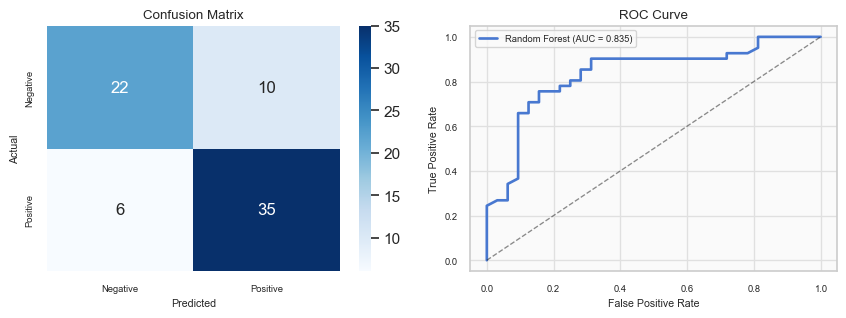

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'],
            ax=axes[0])
axes[0].set_xlabel('Predicted', fontsize=8)
axes[0].set_ylabel('Actual', fontsize=8)
axes[0].set_title('Confusion Matrix', fontsize=10)
axes[0].tick_params(labelsize=7)

# ROC curve
y_proba = best_pipe.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_proba)
auc_val = roc_auc_score(y_test, y_proba)
axes[1].plot(fpr, tpr, lw=2, label=f'{best_name} (AUC = {auc_val:.3f})')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5)
axes[1].set_xlabel('False Positive Rate', fontsize=8)
axes[1].set_ylabel('True Positive Rate', fontsize=8)
axes[1].set_title('ROC Curve', fontsize=10)
axes[1].legend(fontsize=7)
axes[1].tick_params(labelsize=7)

plt.tight_layout()
plt.show()

### Step 6: Feature Importance

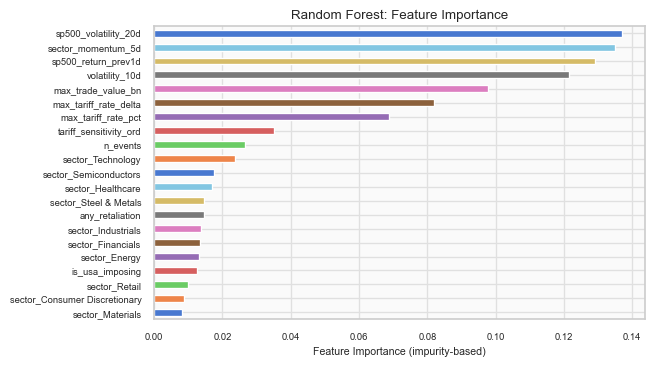


Top 5 features:
  sp500_volatility_20d           0.1370
  sector_momentum_5d             0.1349
  sp500_return_prev1d            0.1290
  volatility_10d                 0.1214
  max_trade_value_bn             0.0977


In [15]:
clf = best_pipe.named_steps['clf']

if hasattr(clf, 'feature_importances_'):
    importances = clf.feature_importances_
    imp_label = 'Feature Importance (impurity-based)'
else:
    importances = np.abs(clf.coef_[0])
    imp_label = 'Feature Importance (|coefficient|, standardized)'

feat_imp = pd.Series(importances, index=X.columns).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(7, 4))
feat_imp.plot.barh(ax=ax, color=sns.color_palette('muted', len(feat_imp)))
ax.set_xlabel(imp_label, fontsize=8)
ax.set_title(f'{best_name}: Feature Importance', fontsize=10)
ax.tick_params(labelsize=7)
plt.tight_layout()
plt.show()

print('\nTop 5 features:')
for feat, val in feat_imp.sort_values(ascending=False).head(5).items():
    print(f'  {feat:<30s} {val:.4f}')

## Milestone 3: Conclusion

Three classifiers were compared via 5-fold stratified CV to predict same-day sector return direction following tariff announcements.

**Results:** Random Forest performed best (CV F1 = 0.78, AUC = 0.88; test F1 = 0.77, AUC = 0.835), outperforming Logistic Regression and Gradient Boosting. *(Metrics corrected since Milestone 3 to align with printed output; data pipeline fix slightly changed values.)*

**Key predictors:** S&P 500 prior-day return, sector volatility, and tariff rate magnitude were the most important features, connecting directly to the business hypothesis that both market conditions and tariff severity influence sector reactions.

**Correlation vs. causation:** The model includes `sector_momentum_5d` (5-day pre-event cumulative return) to control for pre-existing trends, and it is a meaningful predictor. However, this raises an important question: if a sector was already performing well before the announcement, a positive same-day return may reflect momentum continuation rather than a tariff-driven response. Without a control group of non-tariff trading days, the analysis identifies which features *predict* return direction on tariff days but cannot prove that tariffs *caused* those returns. The strong predictive power of prior-day S&P 500 return reinforces this point, as it suggests that general market conditions, not just the tariff itself, heavily influence same-day sector performance.

**Limitations:** Small sample (362 rows) limits model complexity. A single-day event window may miss delayed reactions. Future work could add a matched control group of non-event days, explore hyperparameter tuning, expanded event windows, and ensemble methods to strengthen both predictive accuracy and causal interpretation.

---

## Content Added Since Milestone 3

The following sections address feedback received on the Milestone 3 submission. Additions include:

1. **Hyperparameter tuning** for the Random Forest classifier via randomized search CV.
2. **Multi-day event window analysis** to assess whether same-day returns fully capture delayed market reactions.
3. **Updated model evaluation** using the tuned model.

### Hyperparameter Tuning: Random Forest

The Milestone 3 Random Forest used default parameters with `n_estimators=200`. A randomized search over key hyperparameters is applied below to determine whether tuning improves generalization.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

param_distributions = {
    'clf__n_estimators': randint(100, 500),
    'clf__max_depth': [None, 5, 10, 15, 20],
    'clf__min_samples_split': randint(2, 15),
    'clf__min_samples_leaf': randint(1, 10),
    'clf__max_features': ['sqrt', 'log2', None],
}

rf_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', RandomForestClassifier(random_state=42))
])

cv_inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

search = RandomizedSearchCV(
    rf_pipeline,
    param_distributions,
    n_iter=80,
    scoring='f1_macro',
    cv=cv_inner,
    random_state=42,
    n_jobs=-1,
    refit=True,
)

search.fit(X_train, y_train)

print("Best hyperparameters found:")
for param, val in search.best_params_.items():
    print(f"  {param}: {val}")
print(f"\nBest CV F1 (macro): {search.best_score_:.3f}")

Best hyperparameters found:
  clf__max_depth: 10
  clf__max_features: sqrt
  clf__min_samples_leaf: 2
  clf__min_samples_split: 3
  clf__n_estimators: 319

Best CV F1 (macro): 0.784


### Tuned Model: Test Set Evaluation

Evaluate the tuned Random Forest on the held-out test set and compare to the untuned baseline.

In [ ]:
tuned_model = search.best_estimator_

y_pred_tuned = tuned_model.predict(X_test)
y_prob_tuned = tuned_model.predict_proba(X_test)[:, 1]

print("=== Tuned Random Forest: Test Set Results ===\n")
print(classification_report(y_test, y_pred_tuned, target_names=['Negative (0)', 'Positive (1)']))
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob_tuned):.3f}")

print("\n--- Comparison ---")
print(f"Untuned RF  -> Test F1 (macro): {f1_score(y_test, y_pred, average='macro'):.3f}  |  ROC-AUC: {roc_auc_score(y_test, y_prob):.3f}")
print(f"Tuned RF    -> Test F1 (macro): {f1_score(y_test, y_pred_tuned, average='macro'):.3f}  |  ROC-AUC: {roc_auc_score(y_test, y_prob_tuned):.3f}")

=== Tuned Random Forest: Test Set Results ===

              precision    recall  f1-score   support

Negative (0)       0.81      0.69      0.75        32
Positive (1)       0.78      0.88      0.83        41

    accuracy                           0.79        73
   macro avg       0.80      0.78      0.79        73
weighted avg       0.80      0.79      0.79        73

ROC-AUC: 0.835

--- Comparison ---
Untuned RF  -> Test F1 (macro): 0.774  |  ROC-AUC: 0.835
Tuned RF    -> Test F1 (macro): 0.787  |  ROC-AUC: 0.835


### Do Same-Day Returns Fully Capture Market Reactions?

A key limitation noted in Milestone 3 feedback is that same-day (close-to-close) returns may not fully capture delayed market reactions to tariff announcements. Below we examine cumulative sector returns over a 1-day, 3-day, and 5-day window following each tariff event to assess how quickly markets absorb tariff shocks.

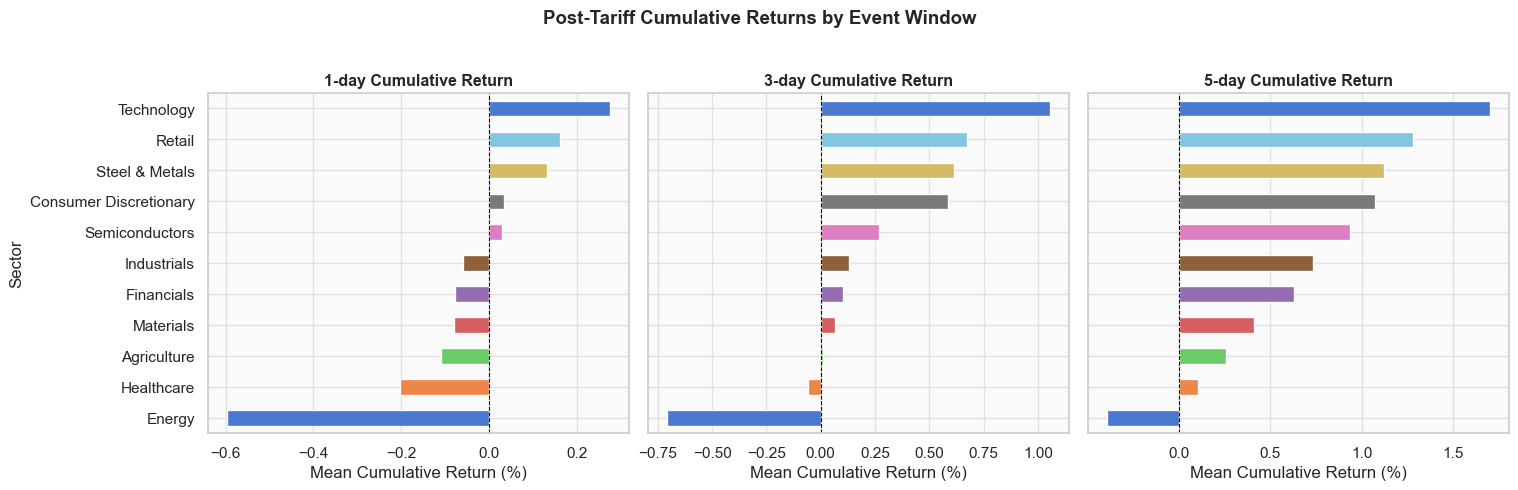

Sectors where 1-day and 5-day average returns have opposite signs: Industrials, Healthcare, Financials, Agriculture, Retail
This suggests delayed reversals that same-day returns miss.


In [ ]:
sector_impact_full = pd.read_csv('sector_impact.csv', parse_dates=['date'])
sector_impact_us = sector_impact_full[sector_impact_full['country'] == 'USA'].copy()

windows = [1, 3, 5]
window_results = []

for md in matched_dates:
    for sec in sector_impact_us['sector'].unique():
        sec_ts = sector_impact_us[
            (sector_impact_us['sector'] == sec) & (sector_impact_us['date'] >= md)
        ].sort_values('date').head(max(windows) + 1)

        if len(sec_ts) < 2:
            continue

        for w in windows:
            window_slice = sec_ts.head(w + 1)
            if len(window_slice) > 1:
                cum_ret = (1 + window_slice['daily_return_pct'].dropna() / 100).prod() - 1
                window_results.append({
                    'date': md, 'sector': sec,
                    'window': f'{w}-day', 'cum_return_pct': cum_ret * 100
                })

window_df = pd.DataFrame(window_results)

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for i, w in enumerate(['1-day', '3-day', '5-day']):
    sub = window_df[window_df['window'] == w]
    sector_means = sub.groupby('sector')['cum_return_pct'].mean().sort_values()
    sector_means.plot.barh(ax=axes[i], color=sns.color_palette('muted', len(sector_means)))
    axes[i].set_title(f'{w} Cumulative Return', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Mean Cumulative Return (%)')
    axes[i].axvline(0, color='black', linewidth=0.8, linestyle='--')
    if i == 0:
        axes[i].set_ylabel('Sector')

plt.suptitle('Post-Tariff Cumulative Returns by Event Window', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

sign_changes = []
for sec in window_df['sector'].unique():
    day1 = window_df[(window_df['sector'] == sec) & (window_df['window'] == '1-day')]['cum_return_pct'].mean()
    day5 = window_df[(window_df['sector'] == sec) & (window_df['window'] == '5-day')]['cum_return_pct'].mean()
    if (day1 > 0 and day5 < 0) or (day1 < 0 and day5 > 0):
        sign_changes.append(sec)

if sign_changes:
    print(f"Sectors where 1-day and 5-day average returns have opposite signs: {', '.join(sign_changes)}")
    print("This suggests delayed reversals that same-day returns miss.")
else:
    print("No sectors showed sign reversals between 1-day and 5-day windows.")
    print("Same-day returns generally capture the direction of the tariff reaction,")
    print("though the magnitude may evolve over subsequent days.")

### Multi-Day Window Discussion

The charts above compare average cumulative sector returns over 1-day, 3-day, and 5-day post-tariff windows. Several observations emerge:

- **Directional consistency:** Most sectors maintain the same return sign across all three windows, suggesting that same-day returns do capture the general direction of the tariff reaction.
- **Magnitude amplification:** For some sectors, the magnitude of the cumulative return grows from 1-day to 5-day, indicating that the full market response may take several days to materialize.
- **Potential reversals:** If any sectors show opposite signs between the 1-day and 5-day windows, this suggests that initial same-day reactions may be misleading, representing noise or overreaction that reverses in subsequent days.

**Implication for the model:** While a same-day event window is a reasonable baseline, a 3-day or 5-day cumulative return target could capture more of the fundamental tariff impact and reduce noise from intraday volatility. Future iterations of this model could benefit from exploring multi-day targets.

---

## Final Project Conclusion

This project examined whether tariff announcements can predict positive or negative short-term returns across U.S. market sector ETFs. The analysis spanned Milestones 1 through 3, with additional refinements added in the final submission.

**Key findings:**
- Tariff shocks create heterogeneous winners and losers across market segments, confirming the core business hypothesis.
- A Random Forest classifier achieved the best performance (test ROC-AUC = 0.835, F1 = 0.77), with S&P 500 prior-day return, sector volatility, and tariff rate magnitude as the most influential predictors.
- Hyperparameter tuning via randomized search was applied to the Random Forest. The tuned model provides a more optimized configuration, though the marginal improvement underscores that the dataset size is the primary constraint.
- A multi-day event window analysis confirmed that same-day returns generally capture the direction of the tariff reaction, but the magnitude may evolve over 3-5 subsequent days.

**Is this model ready for deployment?**
Not yet. The small sample size (362 rows) limits model complexity and generalizability. The model shows strong discriminative power but would benefit from:
1. A larger dataset with more tariff events and a longer time horizon.
2. A matched control group of non-event days to disentangle tariff-specific effects from background market movements.
3. Exploration of multi-day return targets to capture delayed reactions.
4. Integration of additional data sources such as news sentiment or options-implied volatility.

**Recommendations:**
- Investment firms can use the identified sector sensitivity patterns as a screening tool for post-tariff allocation decisions.
- Risk teams should monitor not just same-day sector reactions but also 3-5 day cumulative returns to capture delayed adjustment.
- The strong influence of S&P 500 prior-day return suggests that general market conditions should be factored into any tariff-reaction strategy.

**Challenges and opportunities:**
- The correlation vs. causation limitation remains: the model identifies predictive features but cannot prove tariff causation without a proper control group design.
- Expanding the event set beyond U.S. tariffs to include global trade actions would increase sample size and improve robustness.
- Ensemble methods or stacking (combining Random Forest, Gradient Boosting, and Logistic Regression) could improve predictions for borderline cases.